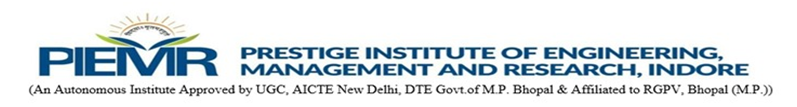

Understanding the dataset
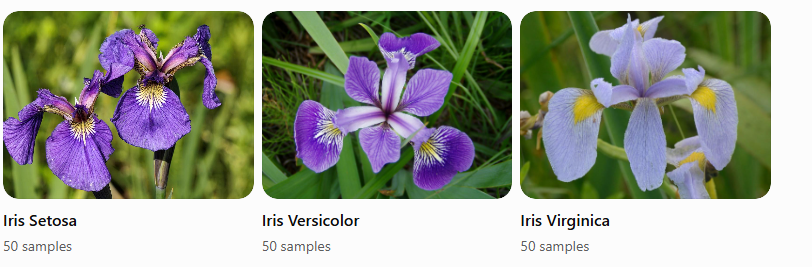

The dataset contains the following features:
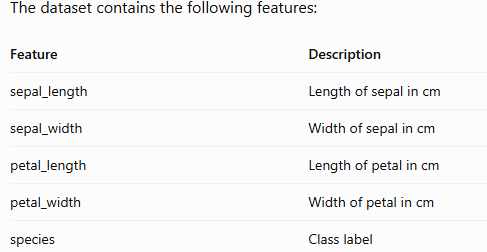

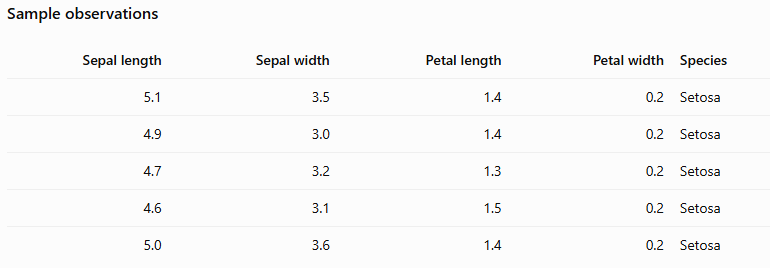

## Aim of the experiment

To implement Principal Component Analysis on the Iris dataset using Python and reduce the dimensionality from four features to two principal components while retaining maximum variance.



In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

In [2]:
df = pd.read_csv("iris_dataset.csv")

print("Dataset Shape:", df.shape)

df.head()

Dataset Shape: (150, 5)


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [3]:
X = df.drop("species", axis=1)

y = df["species"]

print("Input Features:", X.shape)
print("Class Labels:", y.shape)

X.head()

Input Features: (150, 4)
Class Labels: (150,)


,sepal_length,sepal_width,petal_length,petal_width
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


In [4]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("Standardized Dataset:")

print(X_scaled[:5])

Standardized Dataset:
[[-0.90068117  1.01900435 -1.34022653 -1.3154443 ]
 [-1.14301691 -0.13197948 -1.34022653 -1.3154443 ]
 [-1.38535265  0.32841405 -1.39706395 -1.3154443 ]
 [-1.50652052  0.09821729 -1.2833891  -1.3154443 ]
 [-1.02184904  1.24920112 -1.34022653 -1.3154443 ]]


Standardization is performed using:

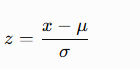

After standardization, each feature has approximately zero mean and unit variance (using population variance).

Significance: It prevents features having larger numerical variation from unnecessarily dominating PCA.

In [5]:
cov_matrix = np.cov(X_scaled.T)

print("Covariance Matrix:")

print(np.round(cov_matrix, 4))

Covariance Matrix:
[[ 1.0067 -0.1184  0.8776  0.8234]
 [-0.1184  1.0067 -0.4313 -0.3686]
 [ 0.8776 -0.4313  1.0067  0.9693]
 [ 0.8234 -0.3686  0.9693  1.0067]]


Here, the covariance matrix will have dimensions:



It represents the relationship between the four original features.


In [6]:
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

print("Original Shape:", X.shape)

print("Reduced Shape:", X_pca.shape)

Original Shape: (150, 4)
Reduced Shape: (150, 2)


In [7]:
print("Eigenvalues:")

print(pca.explained_variance_)

print("\nEigenvectors:")

print(pca.components_)

Eigenvalues:
[2.93808505 0.9201649 ]

Eigenvectors:
[[ 0.52106591 -0.26934744  0.5804131   0.56485654]
 [ 0.37741762  0.92329566  0.02449161  0.06694199]]


In [8]:
variance = pca.explained_variance_ratio_ * 100

print("PC1 Variance:", variance[0])

print("PC2 Variance:", variance[1])

print("Total Variance Retained:", sum(variance))

PC1 Variance: 72.96244541329989
PC2 Variance: 22.850761786701753
Total Variance Retained: 95.81320720000164


In [9]:
pca_df = pd.DataFrame(
    X_pca,
    columns=["PC1", "PC2"]
)

pca_df["species"] = y

pca_df.head()

,PC1,PC2,species
0,-2.264703,0.480027,setosa
1,-2.080961,-0.674134,setosa
2,-2.364229,-0.341908,setosa
3,-2.299384,-0.597395,setosa
4,-2.389842,0.646835,setosa


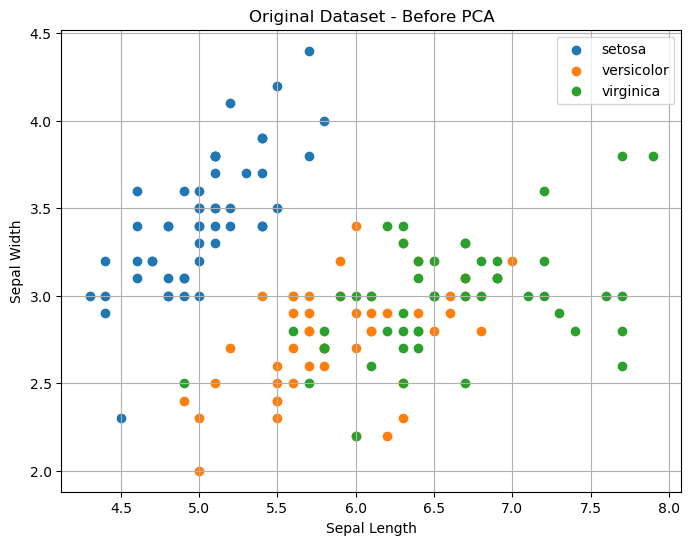

In [10]:
plt.figure(figsize=(8, 6))

for species in df["species"].unique():

    data = df[df["species"] == species]

    plt.scatter(
        data["sepal_length"],
        data["sepal_width"],
        label=species
    )

plt.xlabel("Sepal Length")
plt.ylabel("Sepal Width")
plt.title("Original Dataset - Before PCA")
plt.legend()
plt.grid()
plt.show()

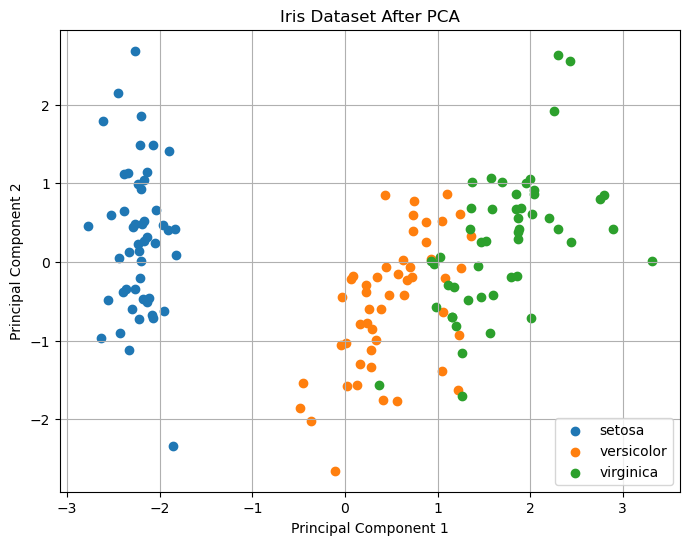

In [11]:
plt.figure(figsize=(8, 6))

for species in pca_df["species"].unique():

    data = pca_df[pca_df["species"] == species]

    plt.scatter(
        data["PC1"],
        data["PC2"],
        label=species
    )

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("Iris Dataset After PCA")
plt.legend()
plt.grid()
plt.show()

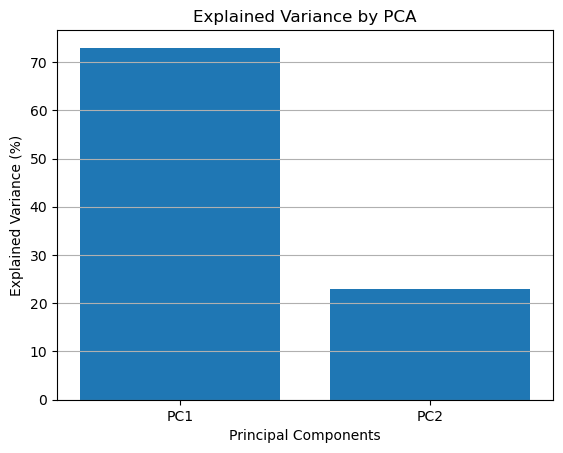

In [12]:
plt.bar(
    ["PC1", "PC2"],
    pca.explained_variance_ratio_ * 100
)

plt.xlabel("Principal Components")
plt.ylabel("Explained Variance (%)")
plt.title("Explained Variance by PCA")
plt.grid(axis="y")
plt.show()

In [13]:
pca_df.to_csv(
    "iris_pca_reduced.csv",
    index=False
)

print("Reduced dataset saved successfully.")

Reduced dataset saved successfully.


## Correlation heatmap

This shows which original features are correlated and why dimensionality reduction may be useful.

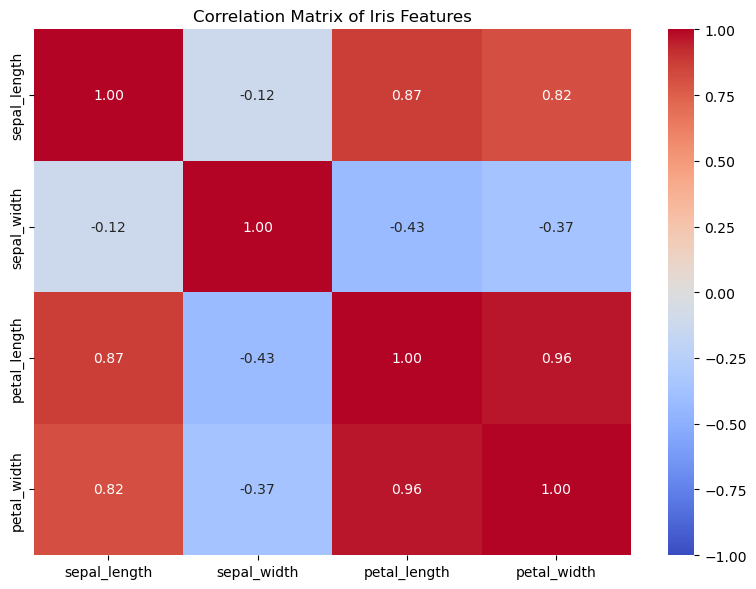

In [14]:
import seaborn as sns

plt.figure(figsize=(8, 6))

sns.heatmap(
    X.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Matrix of Iris Features")
plt.tight_layout()
plt.savefig("correlation_heatmap.png", dpi=300)
plt.show()

## Scree plot

A scree plot displays the eigenvalues in descending order.


For this plot, we must calculate all four principal components instead of just two.


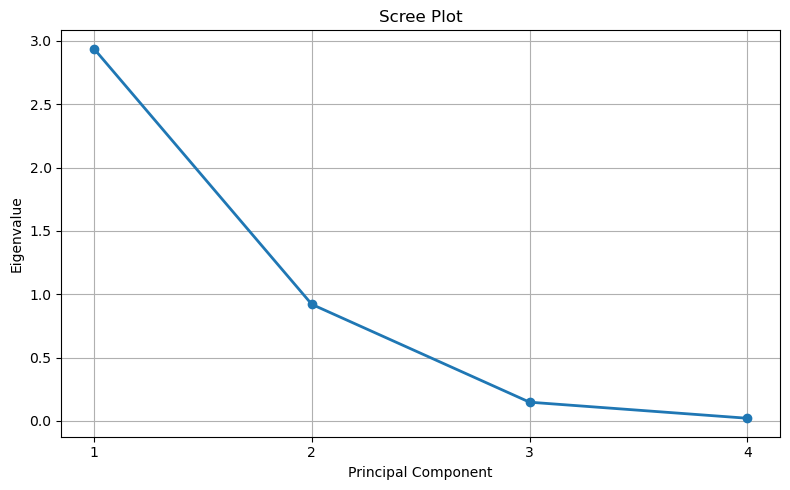

In [15]:
pca_full = PCA(n_components=4)
pca_full.fit(X_scaled)

eigenvalues = pca_full.explained_variance_

plt.figure(figsize=(8, 5))

plt.plot(
    range(1, 5),
    eigenvalues,
    marker="o",
    linewidth=2
)

plt.xlabel("Principal Component")
plt.ylabel("Eigenvalue")
plt.title("Scree Plot")
plt.xticks(range(1, 5))
plt.grid()

plt.tight_layout()
plt.savefig("scree_plot.png", dpi=300)
plt.show()

## Cumulative explained variance plot

This is particularly important because it helps us decide how many principal components should be retained.

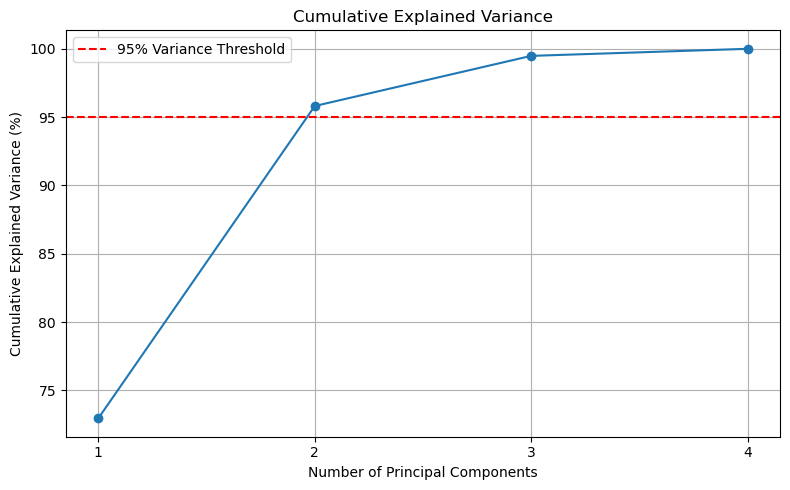

In [16]:
cumulative_variance = np.cumsum(
    pca_full.explained_variance_ratio_
) * 100

plt.figure(figsize=(8, 5))

plt.plot(
    range(1, 5),
    cumulative_variance,
    marker="o"
)

plt.axhline(
    y=95,
    color="red",
    linestyle="--",
    label="95% Variance Threshold"
)

plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance (%)")
plt.title("Cumulative Explained Variance")
plt.xticks(range(1, 5))
plt.legend()
plt.grid()

plt.tight_layout()
plt.savefig("cumulative_variance.png", dpi=300)
plt.show()

## Principal component coefficient plot

This plot explains how each original feature contributes to the formation of PC1 and PC2.

                   PC1       PC2
sepal_length  0.521066  0.377418
sepal_width  -0.269347  0.923296
petal_length  0.580413  0.024492
petal_width   0.564857  0.066942


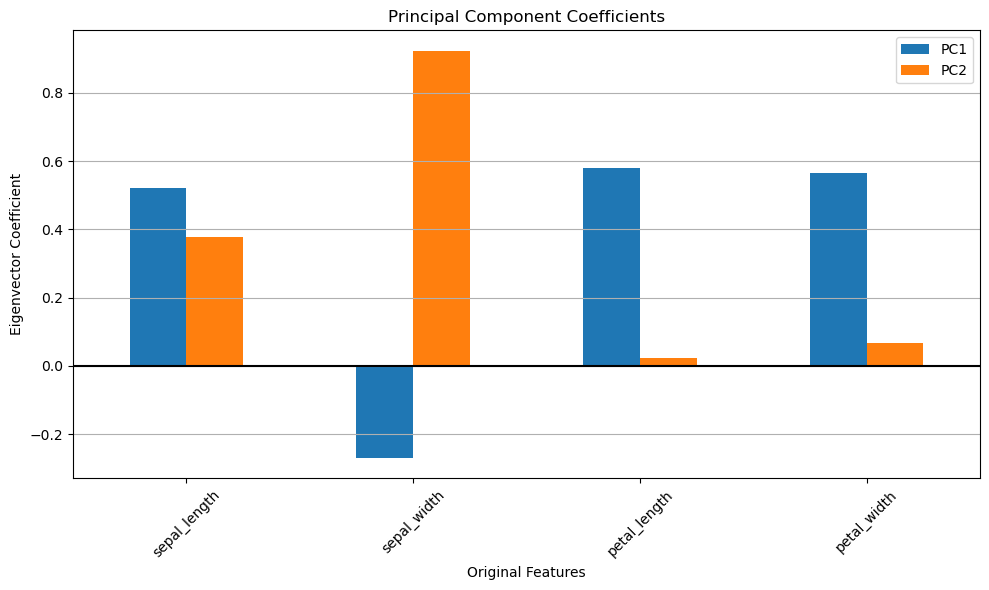

In [17]:
coefficients = pd.DataFrame(
    pca.components_.T,
    columns=["PC1", "PC2"],
    index=X.columns
)

print(coefficients)

coefficients.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.ylabel("Eigenvector Coefficient")
plt.xlabel("Original Features")
plt.title("Principal Component Coefficients")
plt.axhline(0, color="black")
plt.xticks(rotation=45)
plt.grid(axis="y")

plt.tight_layout()
plt.savefig("pca_coefficients.png", dpi=300)
plt.show()

## PCA biplot

A biplot displays both the transformed observations and the original feature directions on the same graph.

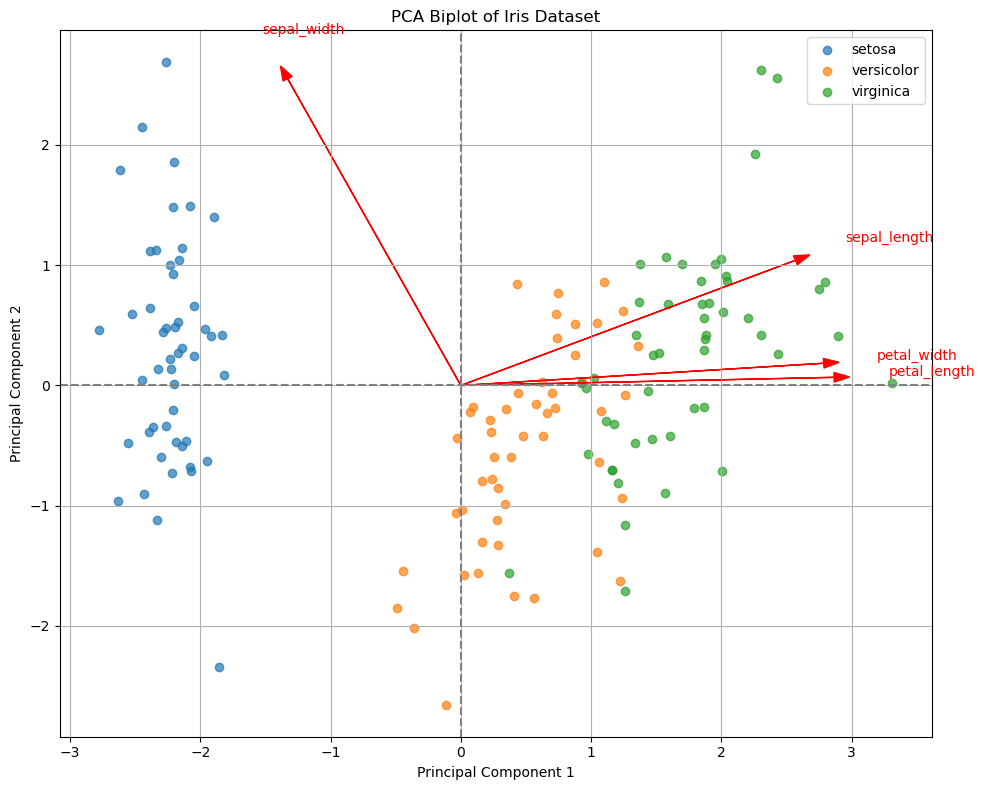

In [18]:
plt.figure(figsize=(10, 8))

for species in pca_df["species"].unique():

    data = pca_df[pca_df["species"] == species]

    plt.scatter(
        data["PC1"],
        data["PC2"],
        label=species,
        alpha=0.7
    )

# Feature loading vectors
loadings = (
    pca.components_.T *
    np.sqrt(pca.explained_variance_)
)

scale = 3

for i, feature in enumerate(X.columns):

    x = loadings[i, 0] * scale
    y = loadings[i, 1] * scale

    plt.arrow(
        0, 0, x, y,
        color="red",
        head_width=0.08,
        length_includes_head=True
    )

    plt.text(
        x * 1.1,
        y * 1.1,
        feature,
        color="red"
    )

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA Biplot of Iris Dataset")

plt.axhline(0, color="gray", linestyle="--")
plt.axvline(0, color="gray", linestyle="--")

plt.legend()
plt.grid()
plt.tight_layout()

plt.savefig("pca_biplot.png", dpi=300)
plt.show()

## Reconstruction error plot

This plot demonstrates what happens to the original dataset when we discard principal components.

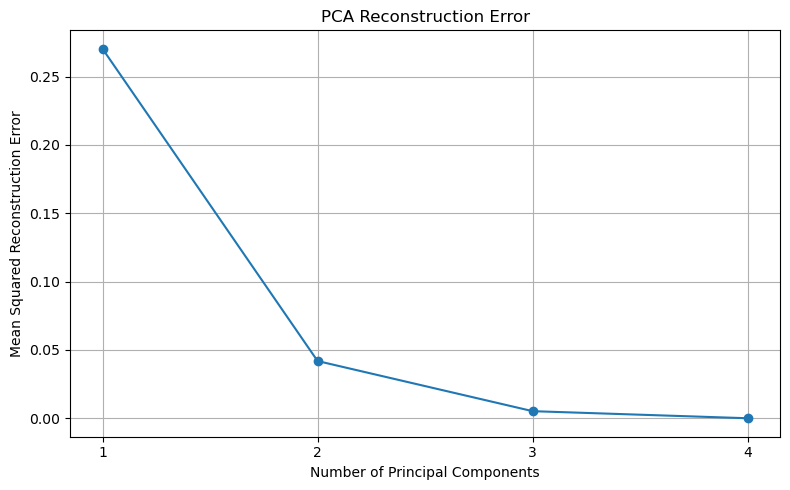

In [19]:
errors = []

for k in range(1, 5):

    model = PCA(n_components=k)

    X_reduced = model.fit_transform(X_scaled)

    X_reconstructed = model.inverse_transform(
        X_reduced
    )

    mse = np.mean(
        (X_scaled - X_reconstructed)**2
    )

    errors.append(mse)

plt.figure(figsize=(8, 5))

plt.plot(
    range(1, 5),
    errors,
    marker="o"
)

plt.xlabel("Number of Principal Components")
plt.ylabel("Mean Squared Reconstruction Error")
plt.title("PCA Reconstruction Error")
plt.xticks(range(1, 5))
plt.grid()

plt.tight_layout()
plt.savefig("reconstruction_error.png", dpi=300)
plt.show()

In [20]:
plt.savefig(
    "original_dataset.png",
    dpi=300,
    bbox_inches="tight"
)

<Figure size 640x480 with 0 Axes>

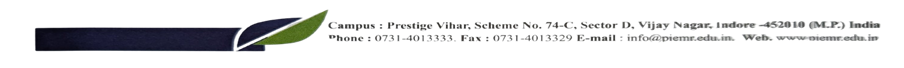